# BRD4–BD2 | QSAR model performance and diagnostics

**Model:** Morgan ECFP4 (radius 2; 2,048 bits), RBF-SVR. **Evaluation:** 187-compound scaffold-separated holdout, 20 repeated scaffold-split assessments, 30 y-randomization runs, and fold-derived AD diagnostics.

This notebook **recalculates and visualizes pre-existing model outputs**. It does **not** rerun hyperparameter optimization or claim fresh retraining. All reported results come from saved CSV files and are recomputed or checked in the cells below. Computational potency predictions are not experimental confirmations.

**Figure style:** DejaVu Sans; bold 15-pt axis labels; bold 12-pt tick labels; 2-pt spines; contrasting colors; no chart titles or grid; separate figures; exported at 600 dpi in PNG plus PDF/SVG. Figures are embedded here at screen resolution for browsing.

## 1. Load input files and set the approved figure style

Run from the repository root. Required CSVs are in `BD2/validation/`, `BD2/data/`, and `BD2/screening/`. The original research execution paths are accepted only as local fallbacks.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator
from IPython.display import display
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import spearmanr

ROOT=Path.cwd()
def locate(*candidates):
    for candidate in candidates:
        p=Path(candidate)
        if p.is_file(): return p
    raise FileNotFoundError('Missing required input. Tried: '+', '.join(map(str,candidates)))

hold_path=locate('BD2/validation/heldout_predictions_with_AD.csv', '/mnt/data/BRD4_BD2_QSAR_RESULTS/heldout_predictions_with_AD.csv')
repeat_path=locate('BD2/validation/repeated_scaffold_20x_metrics.csv', '/mnt/data/BRD4_BD2_QSAR_RESULTS/repeated_scaffold_20x_metrics.csv')
yrand_path=locate('BD2/validation/y_randomization_30x.csv', '/mnt/data/BRD4_BD2_QSAR_RESULTS/y_randomization_30x.csv')
oof_path=locate('BD2/validation/development_repeated_scaffold_oof_predictions.csv', '/mnt/data/BRD4_BD2_AD_CALIBRATION/development_repeated_scaffold_oof_predictions.csv')
fda_path=locate('BD2/screening/BD2_FDA_all_predictions.csv', '/mnt/data/BRD4_BD2_FDA_SCREENING/BD2_FDA_all_predictions.csv')

hold=pd.read_csv(hold_path); reps=pd.read_csv(repeat_path); yrand=pd.read_csv(yrand_path)
oof=pd.read_csv(oof_path); fda=pd.read_csv(fda_path)

OUT=Path('BD2/figures') if Path('BD2').is_dir() else Path('/mnt/data/BD2_PUBLICATION_FIGURES')
OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':12,'axes.labelsize':15,'axes.labelweight':'bold',
'axes.linewidth':2,'xtick.labelsize':12,'ytick.labelsize':12,'xtick.major.width':1.7,'ytick.major.width':1.7,
'xtick.major.size':6,'ytick.major.size':6,'xtick.direction':'out','ytick.direction':'out',
'figure.dpi':110,'savefig.dpi':600,'axes.grid':False,'pdf.fonttype':42,'svg.fonttype':'none'})
COL={'blue':'#1678C8','orange':'#F28C28','teal':'#06A6A0','purple':'#8B55C9','red':'#D84E58','navy':'#253E66'}
def stylize(ax,xlabel,ylabel):
    ax.set_xlabel(xlabel,fontweight='bold',fontsize=15,labelpad=10)
    ax.set_ylabel(ylabel,fontweight='bold',fontsize=15,labelpad=10)
    for spine in ax.spines.values(): spine.set_linewidth(2)
    ax.tick_params(axis='both',which='major',width=1.7,length=6)
    for t in ax.get_xticklabels()+ax.get_yticklabels():t.set_fontweight('bold');t.set_fontsize(12)
    ax.grid(False)
def publish(fig,filename):
    fig.tight_layout(pad=1.6)
    for ext in ('png','pdf','svg'):
        fig.savefig(OUT/f'{filename}.{ext}',dpi=600,bbox_inches='tight',facecolor='white')
    display(fig)
    plt.close(fig)
print('Files loaded:',len(hold),'held-out;',len(reps),'repeats;',len(yrand),'y-randomizations;',len(oof),'fold predictions;',len(fda),'FDA drugs')

Files loaded: 187 held-out; 20 repeats; 30 y-randomizations; 2520 fold predictions; 1764 FDA drugs


## 2. Held-out QSAR performance metrics

`R²` measures variance explained; `RMSE` and `MAE` are in **pIC₅₀ units**. Bias is mean predicted minus observed potency. The holdout is independent of model selection. Split-to-split variation is reported separately (not pooled as a second holdout).

In [2]:
obs=hold['observed_pIC50'].to_numpy();pred=hold['predicted_pIC50'].to_numpy()
err=pred-obs;abserr=np.abs(err)
held_metrics={'n':len(hold),'R²':r2_score(obs,pred),'RMSE':np.sqrt(mean_squared_error(obs,pred)),
              'MAE':mean_absolute_error(obs,pred),'Bias':err.mean()}
repeat_metrics={'n':len(reps),'R²':reps.r2.mean(),'RMSE':reps.rmse.mean(),'MAE':reps.mae.mean(),'Bias':reps.bias.mean()}
metrics=pd.DataFrame([held_metrics,repeat_metrics],index=['Locked scaffold holdout','Repeated scaffold splits (mean)'])
display(metrics.round(4))
assert len(hold)==187 and len(reps)==20 and len(yrand)==30 and len(oof)==2520
assert abs(held_metrics['R²']-0.6774265)<0.0001
print('Repeated-split R² SD:',round(reps.r2.std(ddof=1),4))

,n,R²,RMSE,MAE,Bias
Locked scaffold holdout,187,0.6774,0.7329,0.5763,0.0597
Repeated scaffold splits (mean),20,0.6466,0.7136,0.5556,0.0135


Repeated-split R² SD: 0.0729


## Figure 1. Observed versus predicted pIC₅₀

The diagonal is ideal prediction. Points far from it represent large potency errors. The held-out set contains 187 compounds.

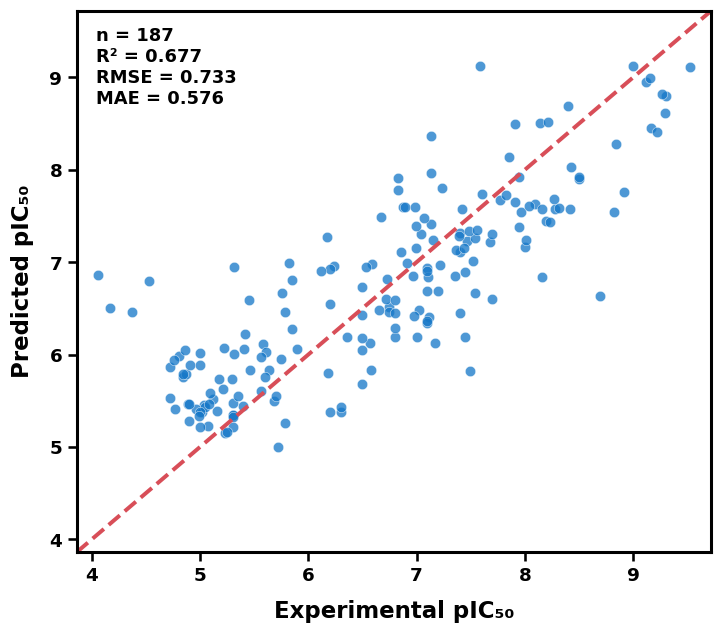

In [3]:
fig,ax=plt.subplots(figsize=(6.9,6.1))
ax.scatter(obs,pred,s=46,color=COL['blue'],alpha=.76,edgecolors='white',linewidths=.35)
lims=[min(obs.min(),pred.min())-.20,max(obs.max(),pred.max())+.20]
ax.plot(lims,lims,color=COL['red'],lw=2.6,ls='--',label='Ideal prediction')
ax.set_xlim(lims);ax.set_ylim(lims)
stylize(ax,'Experimental pIC₅₀','Predicted pIC₅₀')
ax.text(.03,.97,f'n = {len(obs)}\nR² = {held_metrics["R²"]:.3f}\nRMSE = {held_metrics["RMSE"]:.3f}\nMAE = {held_metrics["MAE"]:.3f}',transform=ax.transAxes,va='top',fontsize=11.7,fontweight='bold',bbox={'facecolor':'white','edgecolor':'none','alpha':.9})
publish(fig,'Figure_01_Heldout_Parity')

## Figure 2. Residual error versus predicted potency

`Residual = predicted − experimental pIC₅₀`. Values above zero are overpredictions; below zero are underpredictions. No systematic shift should be assumed from an overall bias near zero.

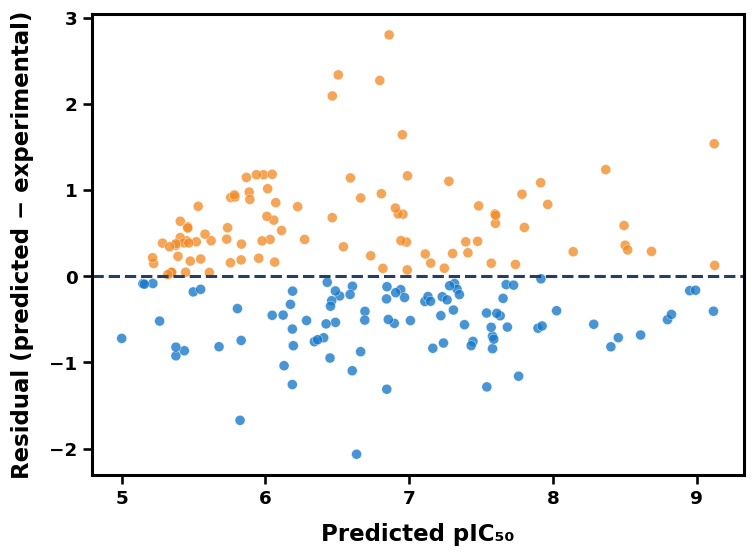

In [4]:
fig,ax=plt.subplots(figsize=(7.2,5.4))
ax.scatter(pred,err,s=43,c=np.where(err>=0,COL['orange'],COL['blue']),alpha=.78,edgecolors='white',linewidths=.3)
ax.axhline(0,color=COL['navy'],lw=2,ls='--')
stylize(ax,'Predicted pIC₅₀','Residual (predicted − experimental)')
publish(fig,'Figure_02_Residual_vs_Predicted')

## Figure 3. Distribution of held-out residuals

This checks error asymmetry and tail behavior that a single R² cannot show.

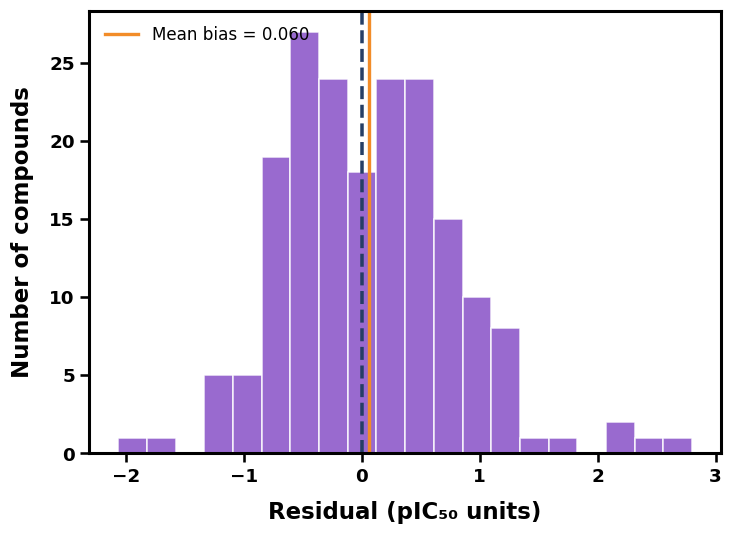

In [5]:
fig,ax=plt.subplots(figsize=(7.0,5.2))
ax.hist(err,bins=20,color=COL['purple'],edgecolor='white',linewidth=1.0,alpha=.88)
ax.axvline(0,color=COL['navy'],lw=2.3,ls='--')
ax.axvline(np.mean(err),color=COL['orange'],lw=2.2,label=f'Mean bias = {err.mean():.3f}')
stylize(ax,'Residual (pIC₅₀ units)','Number of compounds')
ax.legend(frameon=False,fontsize=11,loc='upper left')
publish(fig,'Figure_03_Residual_Distribution')

## Figure 4. Held-out absolute error versus observed potency

A potency-dependent error pattern would reveal limitations obscured by an overall MAE.

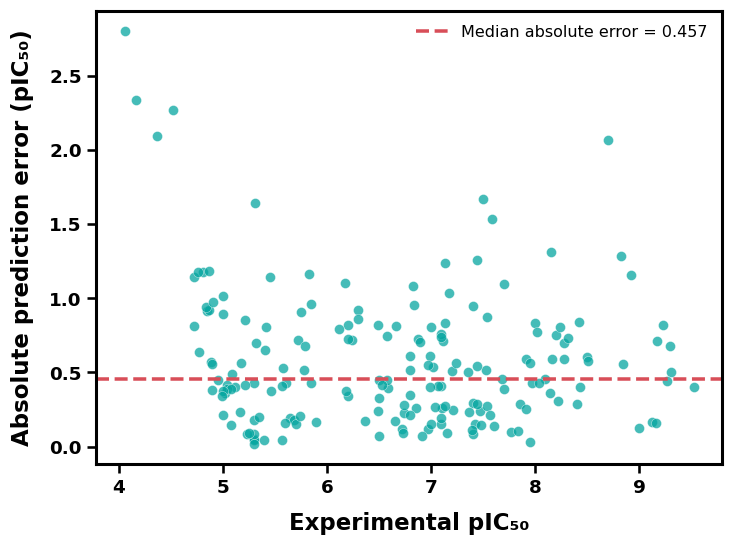

In [6]:
fig,ax=plt.subplots(figsize=(7.0,5.3))
ax.scatter(obs,abserr,c=COL['teal'],s=43,alpha=.75,edgecolors='white',linewidths=.3)
ax.axhline(np.median(abserr),color=COL['red'],lw=2.3,ls='--',label=f'Median absolute error = {np.median(abserr):.3f}')
stylize(ax,'Experimental pIC₅₀','Absolute prediction error (pIC₅₀)')
ax.legend(frameon=False,fontsize=10.5)
publish(fig,'Figure_04_Absolute_Error_vs_Potency')

## 3. Repeated scaffold-split validation

These 20 split-level metrics show stability of performance under changing scaffold allocations. Because training partitions overlap, individual split scores are **not independent biological replicates**.

In [7]:
display(reps[['repeat','test_n','r2','rmse','mae']].round(3))
print(f'R²: {reps.r2.mean():.3f} ± {reps.r2.std(ddof=1):.3f} (SD); range {reps.r2.min():.3f}–{reps.r2.max():.3f}')

,repeat,test_n,r2,rmse,mae
0,1,124,0.505,0.833,0.637
1,2,94,0.521,0.820,0.626
2,3,105,0.637,0.776,0.571
3,4,141,0.652,0.771,0.616
4,5,127,0.710,0.623,0.501
5,6,113,0.639,0.708,0.553
6,7,124,0.581,0.756,0.597
7,8,153,0.644,0.647,0.510
8,9,138,0.725,0.637,0.487
9,10,111,0.651,0.676,0.511


R²: 0.647 ± 0.073 (SD); range 0.505–0.767


## Figure 5. R² across the 20 scaffold splits

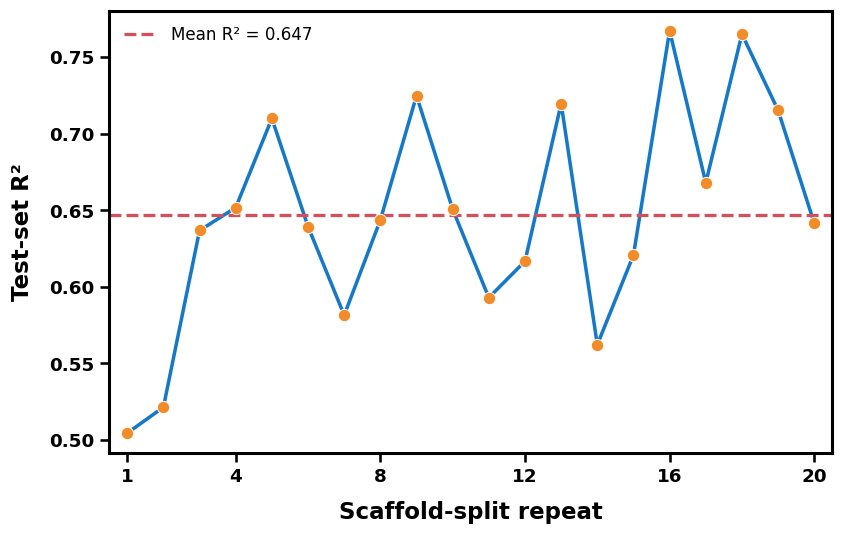

In [8]:
fig,ax=plt.subplots(figsize=(8.0,5.2))
ax.plot(reps['repeat'],reps.r2,color=COL['blue'],lw=2.3,zorder=2)
ax.scatter(reps['repeat'],reps.r2,c=COL['orange'],s=65,zorder=3,edgecolors='white',lw=.6)
ax.axhline(reps.r2.mean(),color=COL['red'],ls='--',lw=2.1,label=f'Mean R² = {reps.r2.mean():.3f}')
ax.set_xticks([1,4,8,12,16,20]);ax.set_xlim(.5,20.5)
stylize(ax,'Scaffold-split repeat','Test-set R²')
ax.legend(frameon=False,fontsize=11)
publish(fig,'Figure_05_Repeated_Scaffold_R2')

## Figure 6. Cross-split distributions of model metrics

Each bar shows the **mean across the 20 splits**, with ±1 sample standard deviation. Metric axes use their own scales; unlike a shared grouped chart, each metric is interpretable.

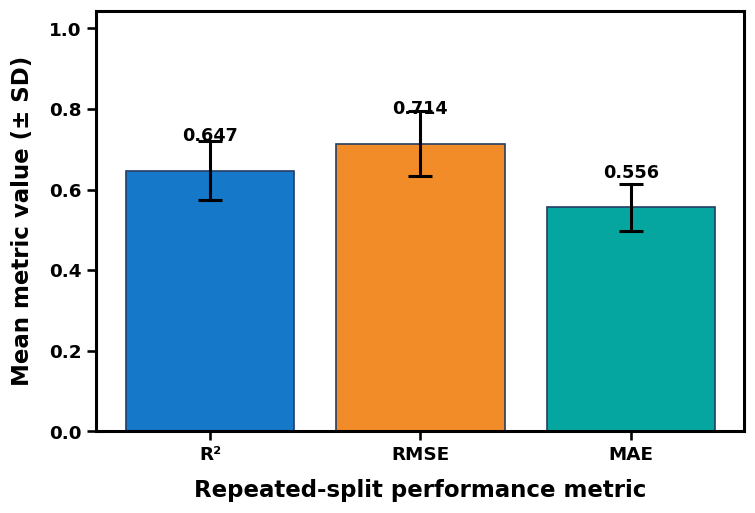

In [9]:
fig,ax=plt.subplots(figsize=(7.2,5.0))
labels=['R²','RMSE','MAE']; vals=[reps.r2.mean(),reps.rmse.mean(),reps.mae.mean()]
std=[reps.r2.std(ddof=1),reps.rmse.std(ddof=1),reps.mae.std(ddof=1)]
ax.bar(labels,vals,yerr=std,capsize=8,color=[COL['blue'],COL['orange'],COL['teal']],edgecolor=COL['navy'],linewidth=1.1,error_kw={'lw':2,'capthick':2})
for i,v in enumerate(vals):ax.text(i,v+.075,f'{v:.3f}',ha='center',fontsize=11.5,fontweight='bold')
ax.set_ylim(0,max(np.array(vals)+np.array(std))+.25)
stylize(ax,'Repeated-split performance metric','Mean metric value (± SD)')
publish(fig,'Figure_06_Repeated_Scaffold_Metrics')

## 4. Y-randomization control

Compare the trained-model held-out R² against models trained after activity-label shuffling. The null scores are retrospective computational controls, not independent experimental measurements.

In [10]:
print('Holdout R²:',round(held_metrics['R²'],4),'| Y-randomized mean R²:',round(yrand.r2.mean(),4),'| Max randomized R²:',round(yrand.r2.max(),4))
display(yrand[['seed','r2','rmse','mae']].head(8).round(3))

Holdout R²: 0.6774 | Y-randomized mean R²: -0.3576 | Max randomized R²: 0.1041


,seed,r2,rmse,mae
0,991,-0.595,1.630,1.382
1,992,-0.714,1.689,1.426
2,993,-0.451,1.554,1.276
3,994,-0.463,1.561,1.321
4,995,-0.077,1.339,1.098
5,996,-0.058,1.327,1.072
6,997,-0.596,1.630,1.347
7,998,-0.281,1.460,1.228


## Figure 7. Y-randomization R² versus original model

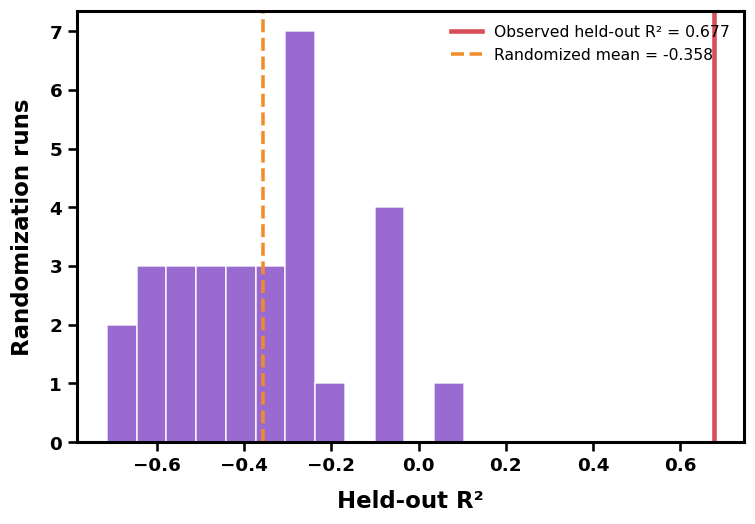

In [11]:
fig,ax=plt.subplots(figsize=(7.2,5.1))
ax.hist(yrand.r2,bins=12,color=COL['purple'],alpha=.88,edgecolor='white',linewidth=1)
ax.axvline(held_metrics['R²'],color=COL['red'],lw=3,label=f'Observed held-out R² = {held_metrics["R²"]:.3f}')
ax.axvline(yrand.r2.mean(),color=COL['orange'],lw=2.3,ls='--',label=f'Randomized mean = {yrand.r2.mean():.3f}')
stylize(ax,'Held-out R²','Randomization runs')
ax.legend(frameon=False,fontsize=10.2,loc='upper right')
publish(fig,'Figure_07_Y_Randomization')

## 5. Applicability-domain analysis from development folds

For each **held-out development-fold prediction**, similarity is computed to that fold’s training structures. This avoids evaluating an observed molecule against itself. A threshold of 0.30 is a *structural screening inclusion rule*, **not** a validated individual prediction confidence limit.

In [12]:
col='nearest_fold_training_tanimoto'; oof['absolute_error_pIC50']=(oof.predicted_pIC50-oof.observed_pIC50).abs()
bins=[0,.2,.3,.4,.5,.6,.7,.8,.9,1.000001];oof['similarity_bin']=pd.cut(oof[col],bins,right=False,include_lowest=True)
bstats=oof.groupby('similarity_bin',observed=True).agg(n=('absolute_error_pIC50','size'),MAE=('absolute_error_pIC50','mean'),RMSE=('absolute_error_pIC50',lambda x:np.sqrt(np.mean(x*x)))).reset_index()
cutoff_rows=[]
for cutoff in [.2,.3,.35,.4,.5,.6,.7]:
    sub=oof.loc[oof[col]>=cutoff,'absolute_error_pIC50']
    cutoff_rows.append({'Tanimoto cutoff':cutoff,'n':len(sub),'coverage':len(sub)/len(oof),'MAE':sub.mean(),'RMSE':np.sqrt(np.mean(sub*sub))})
ct=pd.DataFrame(cutoff_rows)
display(bstats.round(3));display(ct.round(3))
rho,p=spearmanr(oof[col],oof.absolute_error_pIC50)
print(f'Spearman similarity vs absolute error: ρ={rho:.3f}; n={len(oof)} repeated-fold predictions; entries not fully independent')

,similarity_bin,n,MAE,RMSE
0,"[0.0, 0.2)",15,0.357,0.461
1,"[0.2, 0.3)",62,0.900,1.021
2,"[0.3, 0.4)",62,0.891,0.995
3,"[0.4, 0.5)",131,0.718,0.861
4,"[0.5, 0.6)",253,0.899,1.086
5,"[0.6, 0.7)",514,0.580,0.706
6,"[0.7, 0.8)",887,0.490,0.618
7,"[0.8, 0.9)",425,0.372,0.501
8,"[0.9, 1.0)",171,0.415,0.630


,Tanimoto cutoff,n,coverage,MAE,RMSE
0,0.20,2505,0.994,0.557,0.718
1,0.30,2443,0.969,0.548,0.709
2,0.35,2416,0.959,0.543,0.704
3,0.40,2381,0.945,0.539,0.700
4,0.50,2250,0.893,0.529,0.689
5,0.60,1997,0.792,0.482,0.621
6,0.70,1483,0.588,0.448,0.589


Spearman similarity vs absolute error: ρ=-0.346; n=2520 repeated-fold predictions; entries not fully independent


## Figure 8. Similarity-dependent error by independent fold

Points are bin-wise **MAE**, and their corresponding bin sample sizes are displayed above. Low-similarity bins have sparse data; their error does not establish a sharp reliability transition at 0.30.

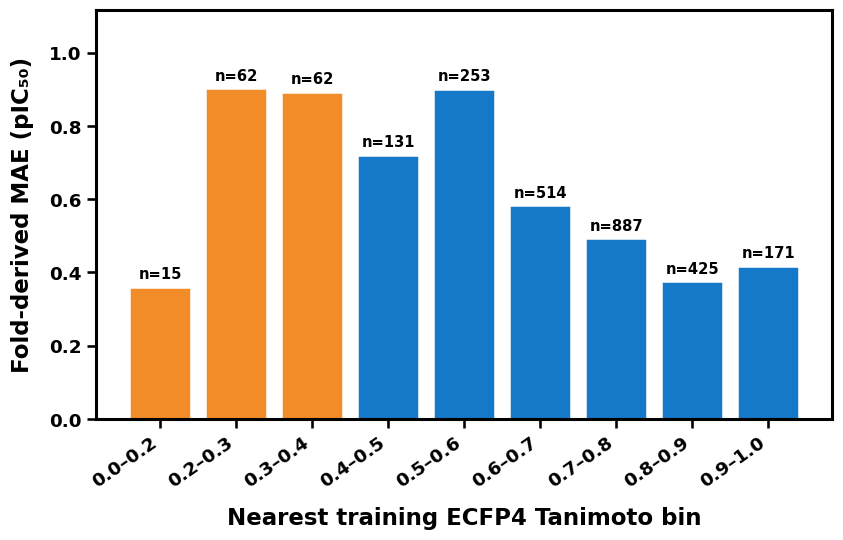

In [13]:
fig,ax=plt.subplots(figsize=(8.0,5.25))
x=np.arange(len(bstats)); ax.bar(x,bstats.MAE,color=[COL['orange'] if i<3 else COL['blue'] for i in range(len(x))],edgecolor='white',linewidth=1)
for i,(v,n) in enumerate(zip(bstats.MAE,bstats.n)):ax.text(i,v+.026,f'n={n}',ha='center',fontsize=9.7,fontweight='bold')
ax.set_xticks(x);ax.set_xticklabels([f'{i.left:.1f}–{i.right:.1f}' for i in bstats.similarity_bin],rotation=35,ha='right')
ax.set_ylim(0,float(bstats.MAE.max())*1.24)
stylize(ax,'Nearest training ECFP4 Tanimoto bin','Fold-derived MAE (pIC₅₀)')
publish(fig,'Figure_08_AD_Binned_Error')

## Figure 9. AD cutoff versus error and development coverage

The accuracy/coverage trade-off should be interpreted alongside how many FDA drugs survive each threshold. Threshold selection is not based on claimed statistical optimality at 0.30.

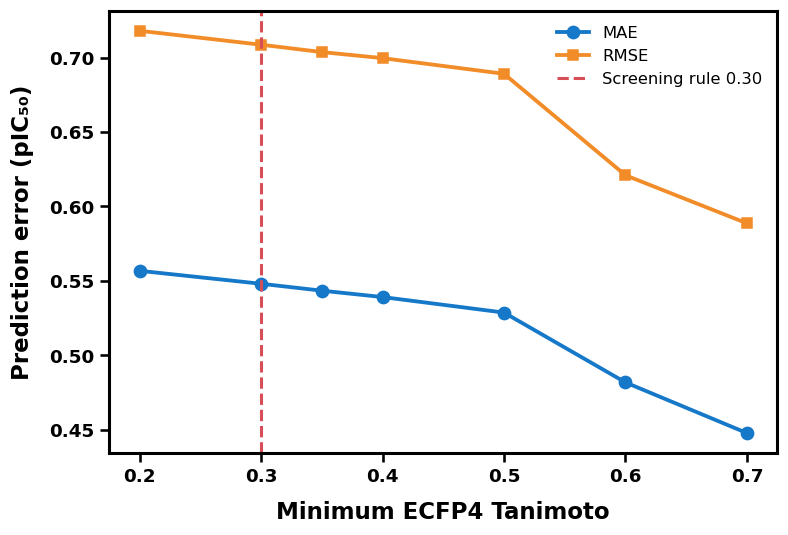

In [14]:
fig,ax=plt.subplots(figsize=(7.5,5.2))
ax.plot(ct['Tanimoto cutoff'],ct.MAE,marker='o',ms=8,lw=2.5,color=COL['blue'],label='MAE')
ax.plot(ct['Tanimoto cutoff'],ct.RMSE,marker='s',ms=7,lw=2.5,color=COL['orange'],label='RMSE')
ax.axvline(.30,color=COL['red'],lw=2,ls='--',label='Screening rule 0.30')
stylize(ax,'Minimum ECFP4 Tanimoto','Prediction error (pIC₅₀)')
ax.legend(frameon=False,fontsize=10.7)
publish(fig,'Figure_09_AD_Cutoff_Error')

## 6. FDA-library structural screening

The current list contains 1,764 DrugCentral snapshot compounds. Predicted pIC₅₀ values are model-derived; screening suitability is **not experimental BRD4-BD2 inhibition**.

In [15]:
n03=int(fda.AD_ge_0p3.sum());n04=int(fda.AD_ge_0p4.sum());n05=int(fda.AD_ge_0p5.sum())
print(f'FDA library {len(fda)}; ECFP4 >=0.30: {n03}; >=0.40: {n04}; >=0.50: {n05}')
assert len(fda)==1764 and n03==33 and n04==2 and n05==0
display(fda.loc[fda.AD_ge_0p3,['drug_name','BD2_pred_pIC50','BD2_pred_IC50_nM','nearest_training_Tanimoto']].head(12).round(3))

FDA library 1764; ECFP4 >=0.30: 33; >=0.40: 2; >=0.50: 0


,drug_name,BD2_pred_pIC50,BD2_pred_IC50_nM,nearest_training_Tanimoto
2,alprazolam,6.807,155.952,0.347
22,triazolam,6.612,244.284,0.324
90,temazepam,6.407,391.931,0.320
144,sulfafurazole,6.344,452.777,0.305
179,retigabine,6.300,501.180,0.305
180,conivaptan,6.300,501.356,0.324
217,diosmetin,6.275,530.357,0.365
261,delavirdine,6.247,566.469,0.329
300,valdecoxib,6.218,605.544,0.317
336,nintedanib,6.196,636.611,0.312


## Figure 10. FDA-approved-drug screening and AD inclusion

This separate figure shows how many drugs meet each structural cutoff. The vertical scale represents counts, not confirmed BRD4 inhibitors.

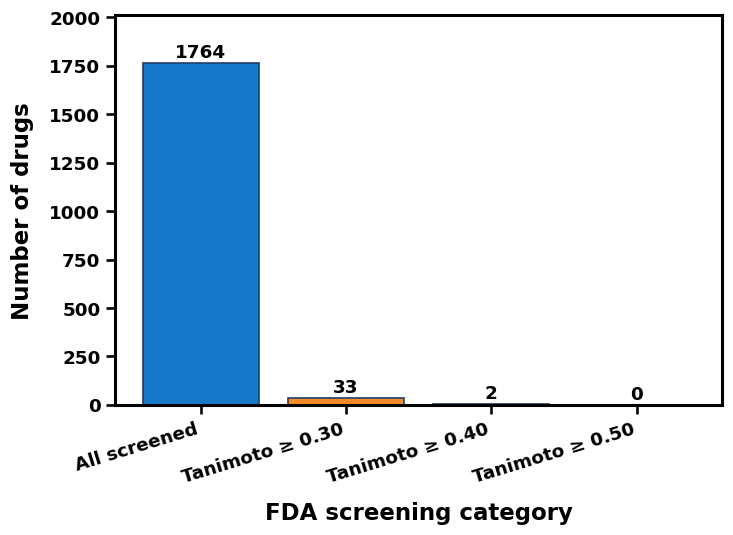

In [16]:
fig,ax=plt.subplots(figsize=(7.0,5.2))
labels=['All screened','Tanimoto ≥ 0.30','Tanimoto ≥ 0.40','Tanimoto ≥ 0.50']
counts=[len(fda),n03,n04,n05]
ax.bar(np.arange(4),counts,color=[COL['blue'],COL['orange'],COL['teal'],COL['purple']],edgecolor=COL['navy'],linewidth=1.1)
for i,v in enumerate(counts):ax.text(i,v+max(counts)*.017,str(v),ha='center',fontsize=12,fontweight='bold')
ax.set_xticks(np.arange(4));ax.set_xticklabels(labels,rotation=17,ha='right')
ax.set_ylim(0,max(counts)*1.14)
stylize(ax,'FDA screening category','Number of drugs')
publish(fig,'Figure_10_FDA_AD_Coverage')

## 7. Export and interpretation

The ten independent figures are exported at 600 dpi in PNG and as vector PDF and SVG. **All evaluation metrics come from saved modeling predictions, not from re-training in this notebook.** Full reproducibility requires the model training pipeline, curated input molecules, locked holdout definitions, and the repeated-fold prediction CSVs.

**Summary:** Locked held-out R² ≈ 0.677, RMSE ≈ 0.733 and MAE ≈ 0.576 pIC₅₀. Twenty scaffold repeats have mean R² ≈ 0.647. Structural inclusion at Tanimoto ≥0.30 yields 33 FDA-library candidates; do not equate structural inclusion with reliable inhibition predictions.